In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
import numpy as np
from utils import  plot_confusion_matrix

In [2]:
main_data = np.load('./tfidf_data.npz',allow_pickle=True)

In [3]:
X = main_data['X']
Y = main_data['y']
Y = np.array(Y)

In [4]:
num_cls = len(set(Y))

In [5]:
from copy import deepcopy
X = deepcopy(X)

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm, metrics
from sklearn.model_selection import StratifiedKFold
from matplotlib.font_manager import FontProperties
plt.rcParams['axes.unicode_minus']=False       #显示负号
plt.rcParams['font.size'] = 12

In [7]:

# set new_roman font
font = FontProperties(family='Times New Roman', size=12)


# define 5-fold cross validation
cv = StratifiedKFold(n_splits=5)


# initialize lists to store results
all_y_true = []
all_y_pred = []
all_y_prob = []

# start 5 cross validation
for train_index, test_index in cv.split(X, Y):
    # split data
    X_train, X_test = X[train_index], X[test_index]
    Y_train, Y_test = Y[train_index], Y[test_index]

    # create and train SVM model
    clf = svm.SVC(kernel='rbf', probability=True)
    clf.fit(X_train, Y_train)

    # predict and get probability
    Y_pred = clf.predict(X_test)
    Y_prob = clf.predict_proba(X_test)

    # collect all results
    all_y_true.extend(Y_test)
    all_y_pred.extend(Y_pred)
    all_y_prob.extend(Y_prob)

# list2numpy
all_y_true = np.array(all_y_true)
all_y_pred = np.array(all_y_pred)
all_y_prob = np.array(all_y_prob)
y_test = all_y_true
y_pred = all_y_pred

In [8]:
mm = 'SVM'

Normalized confusion matrix


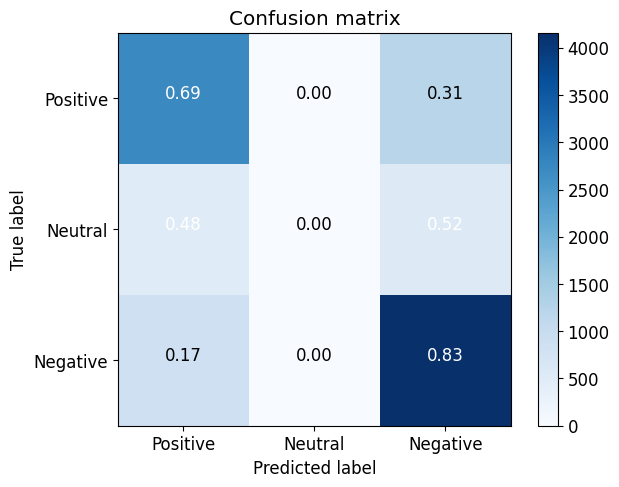

In [9]:
cm = confusion_matrix(y_test, y_pred)
plot_confusion_matrix(cm,classes=['Positive', 'Neutral', 'Negative'],normalize=True,title='Confusion matrix')

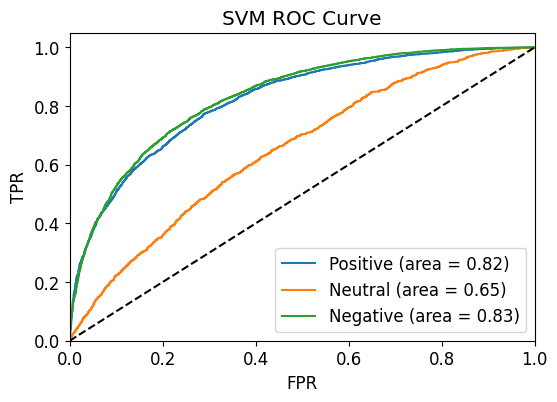

              precision    recall  f1-score   support

           0       0.67      0.69      0.68      3939
           1       0.00      0.00      0.00      1041
           2       0.70      0.83      0.76      5020

    accuracy                           0.69     10000
   macro avg       0.46      0.51      0.48     10000
weighted avg       0.62      0.69      0.65     10000



d:\ProgramData\anaconda3\envs\t\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\ProgramData\anaconda3\envs\t\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\ProgramData\anaconda3\envs\t\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [12]:
CCC = ['Positive', 'Neutral', 'Negative']
fpr = dict()
tpr = dict()
roc_auc = dict()
plt.figure(figsize=(6, 4),dpi=100)
for i in range(num_cls):
    fpr[i], tpr[i], _ = metrics.roc_curve((all_y_true == i).astype(int), all_y_prob[:, i])
    roc_auc[i] = metrics.auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], label=f'{CCC[i]} (area = {roc_auc[i]:0.2f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title(f'{mm} ROC Curve')
plt.legend(loc="lower right")
plt.show()


print(metrics.classification_report(all_y_true, all_y_pred))